# Лабораторна робота №1: Linear Regression
**Мета: навчитись реалізовувати лінійну регресію та градієнтний спуск.**

Виконала: Фролова Валерія Артемівна КН-43 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = np.loadtxt('lab_1_train.csv', delimiter=',', skiprows=1, usecols=(1, 2))
test = np.loadtxt('lab_1_test.csv', delimiter=',', skiprows=1, usecols=(1, 2))

x_train, y_train = train[:, 0], train[:, 1]
x_test, y_test = test[:, 0], test[:, 1]

print("train:", len(x_train), "test:", len(x_test))

train: 60 test: 40


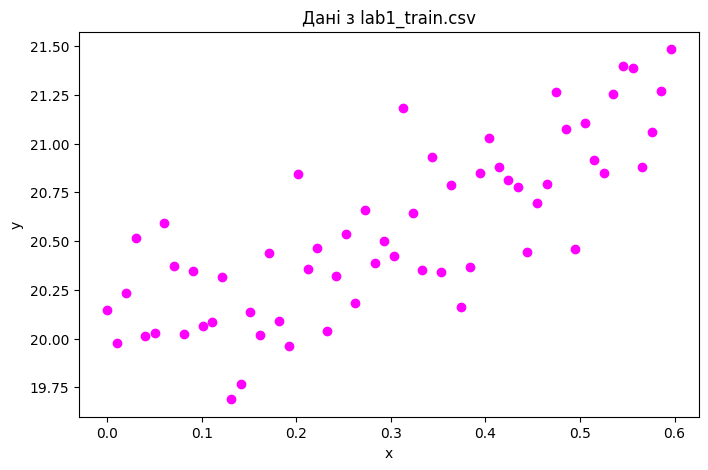

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, color='magenta')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Дані з lab1_train.csv')
plt.show()

In [4]:
def predict(x, w, b):
    return w * x + b

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

learning_rate = 0.5
max_epochs = 10000
grad_tol = 1e-6     
print_every = 1 

w = 0.0
b = 0.0
m = len(x_train)

for epoch in range(1, max_epochs + 1):
    y_pred = predict(x_train, w, b)
    loss = mse(y_train, y_pred)

    error = y_pred - y_train
    grad_w = 2 * np.sum(error * x_train) / m
    grad_b = 2 * np.sum(error) / m
    grad_size = np.sqrt(grad_w ** 2 + grad_b ** 2)

    if epoch == 1 or epoch % print_every == 0:
        print(f"Епоха {epoch:5d} | w = {w:.5f} | b = {b:.5f} | MSE = {loss:.6f}")

    if grad_size < grad_tol:
        print("Градієнтний спуск зійшовся")
        break

    w = w - learning_rate * grad_w
    b = b - learning_rate * grad_b

Епоха     1 | w = 0.00000 | b = 0.00000 | MSE = 422.477402
Епоха     2 | w = 6.18391 | b = 20.54956 | MSE = 4.009614
Епоха     3 | w = 5.50615 | b = 18.70688 | MSE = 0.494564
Епоха     4 | w = 5.45839 | b = 18.90884 | MSE = 0.443738
Епоха     5 | w = 5.35615 | b = 18.92307 | MSE = 0.423012
Епоха     6 | w = 5.26188 | b = 18.95354 | MSE = 0.403659
Епоха     7 | w = 5.16978 | b = 18.98163 | MSE = 0.385378
Епоха     8 | w = 5.08031 | b = 19.00907 | MSE = 0.368108
Епоха     9 | w = 4.99335 | b = 19.03573 | MSE = 0.351793
Епоха    10 | w = 4.90882 | b = 19.06165 | MSE = 0.336380
Епоха    11 | w = 4.82667 | b = 19.08683 | MSE = 0.321819
Епоха    12 | w = 4.74682 | b = 19.11131 | MSE = 0.308063
Епоха    13 | w = 4.66920 | b = 19.13511 | MSE = 0.295068
Епоха    14 | w = 4.59377 | b = 19.15824 | MSE = 0.282791
Епоха    15 | w = 4.52044 | b = 19.18071 | MSE = 0.271193
Епоха    16 | w = 4.44918 | b = 19.20256 | MSE = 0.260237
Епоха    17 | w = 4.37991 | b = 19.22380 | MSE = 0.249886
Епоха    18 |

In [5]:
train_loss = mse(y_train, predict(x_train, w, b))
test_loss = mse(y_test, predict(x_test, w, b))

print(f"Фінальні ваги: w = {w:.5f}, b = {b:.5f}")
print(f"MSE на train: {train_loss:.6f}")
print(f"MSE на test:  {test_loss:.6f}")

Фінальні ваги: w = 1.97880, b = 19.95992
MSE на train: 0.073035
MSE на test:  0.075586


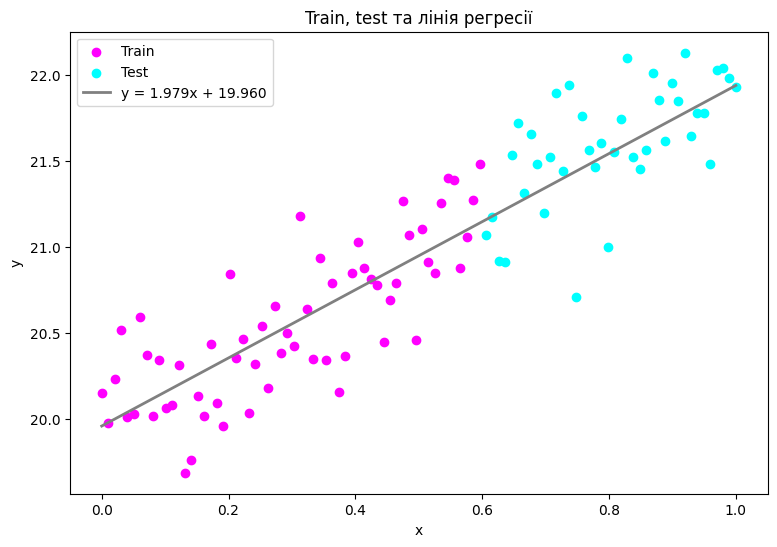

In [6]:
x_line = np.linspace(0, max(x_train.max(), x_test.max()), 100)
y_line = predict(x_line, w, b)

plt.figure(figsize=(9, 6))
plt.scatter(x_train, y_train, color='magenta', label='Train')
plt.scatter(x_test, y_test, color='cyan', label='Test')
plt.plot(x_line, y_line, color='grey', linewidth=2, label=f'y = {w:.3f}x + {b:.3f}')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Train, test та лінія регресії')
plt.legend()
plt.show()